# House Price Prediction


**Machine Learning Project**

**Objective:**  
To analyze house-related features and build machine learning models
to predict house prices accurately.

## 1. Project Introduction

 House Price Prediction is a machine learning project based on the Ames Housing dataset.

The objective of this project is to analyze different characteristics of residential properties and understand their relationship with house prices. The project also aims to develop machine learning models that can predict the sale price of a house based on its features.

The target variable for prediction is `SalePrice`.

## 2. Problem Statement

The objective is to perform a complete analysis of the house price dataset, identify the factors that influence house prices, and build robust machine learning models to accurately predict the sale price of houses.

The project also aims to compare multiple machine learning models and identify the best-performing model for production use.

## 3. Import Libraries

In [36]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

## Loading the Dataset

In [37]:
df =pd.read_csv("data.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 3.1 Dataset Dimensions

In [38]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1460
Number of Columns: 81


### 3.2 Dataset Information

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

### 3.3 Statistical Summary

In [40]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## 4. Data Quality Analysis

### 4.1 Duplicate Values Check

In [63]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


### 4.2 Missing Values Analysis

In [41]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

missing_values

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

### 4.3 Missing Value Percentage

In [42]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)

missing_percentage

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
BsmtExposure     2.602740
BsmtFinType2     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64

## 5. Exploratory Data Analysis

### 5.1  Target Variable Analysis

The target variable of the dataset is `SalePrice`. It represents the final sale price of each house.

In [43]:
df['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

### 5.2 Distribution of Sale Prices

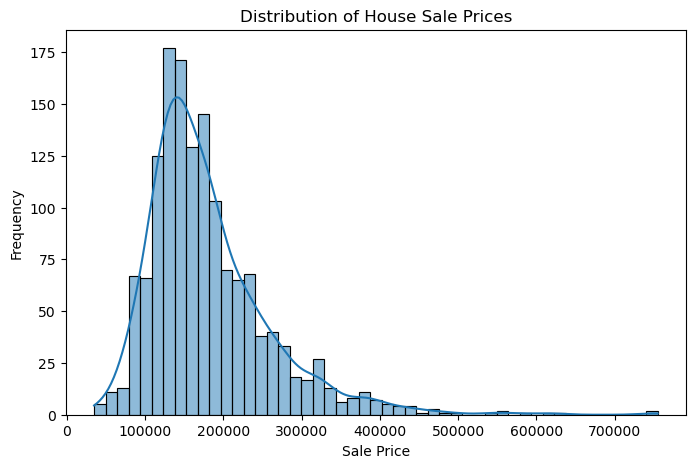

In [44]:
plt.figure(figsize=(8,5))
sns.histplot(df['SalePrice'], kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

### 5.3 Important Features Analysis

In [45]:
important_features = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'GarageArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'YearBuilt'
]

df[important_features + ['SalePrice']].describe()

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,YearBuilt,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,6.099315,1515.463699,1.767123,472.980137,1057.429452,1162.626712,1971.267808,180921.195890
std,1.382997,525.480383,0.747315,213.804841,438.705324,386.587738,30.202904,79442.502883
min,1.000000,334.000000,0.000000,0.000000,0.000000,334.000000,1872.000000,34900.000000
25%,5.000000,1129.500000,1.000000,334.500000,795.750000,882.000000,1954.000000,129975.000000
50%,6.000000,1464.000000,2.000000,480.000000,991.500000,1087.000000,1973.000000,163000.000000
75%,7.000000,1776.750000,2.000000,576.000000,1298.250000,1391.250000,2000.000000,214000.000000
max,10.000000,5642.000000,4.000000,1418.000000,6110.000000,4692.000000,2010.000000,755000.000000


### 5.4 Correlation Analysis

In [46]:
correlation = df.select_dtypes(include=np.number).corr()['SalePrice'].sort_values(ascending=False)

correlation.head(15)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

### 5.5 Correlation Heatmap

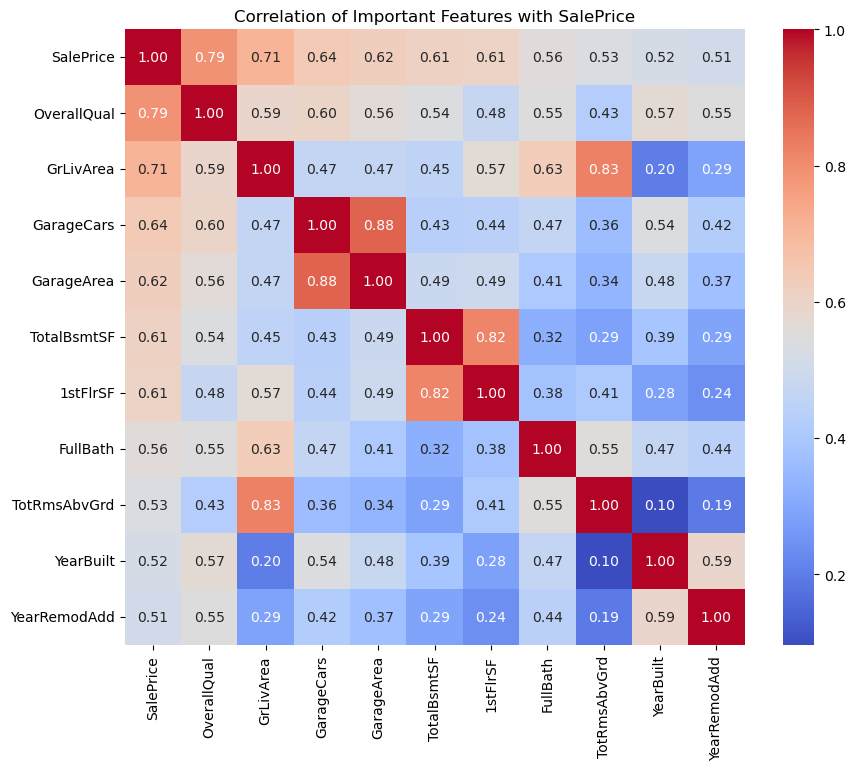

In [47]:
plt.figure(figsize=(10,8))

top_corr_features = correlation.head(11).index

sns.heatmap(
    df[top_corr_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation of Important Features with SalePrice")
plt.show()

### 5.6 Overall Quality vs Sale Price

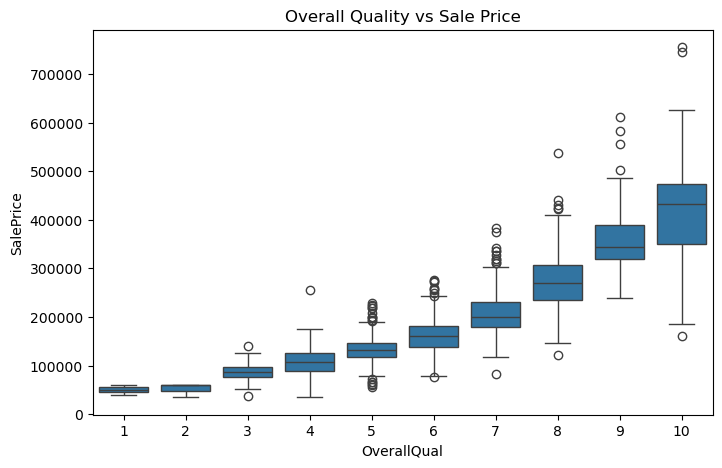

In [48]:
plt.figure(figsize=(8,5))
sns.boxplot(x='OverallQual', y='SalePrice', data=df)
plt.title("Overall Quality vs Sale Price")
plt.show()

### 5.7 Living Area vs Sale Price

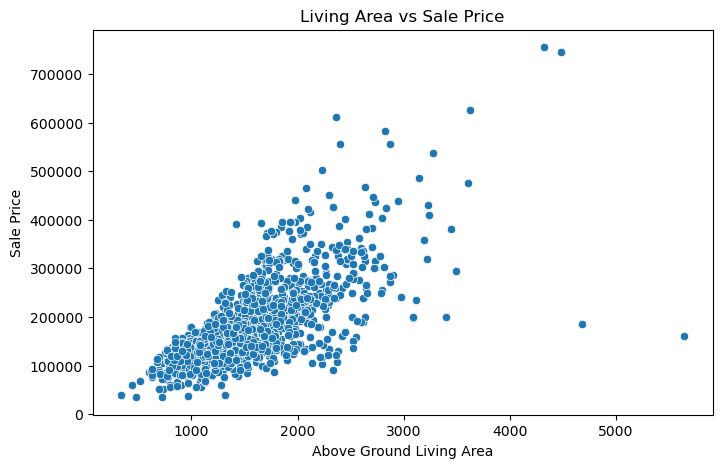

In [49]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='GrLivArea', y='SalePrice', data=df)
plt.title("Living Area vs Sale Price")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")
plt.show()

### 5.8 Year Built vs Sale Price

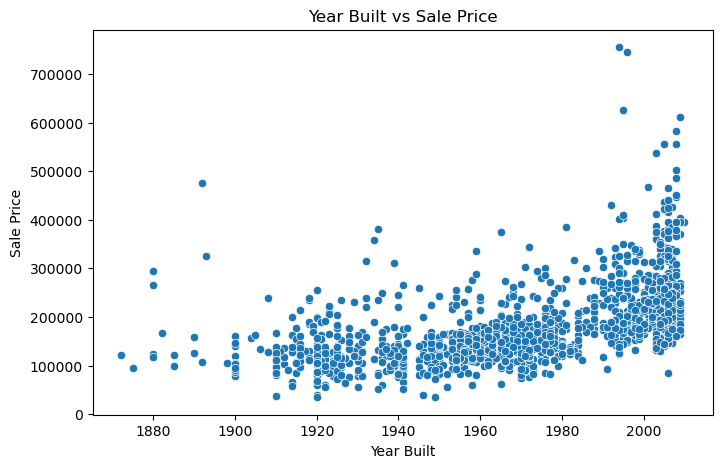

In [50]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='YearBuilt', y='SalePrice', data=df)
plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")
plt.show()

## 6. Data Preprocessing
### 6.1 Separating Features and Target

In [51]:
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1460, 80)
Target shape: (1460,)


### 6.2 Identifying Numerical and Categorical Features

In [52]:
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

Numerical Features: 37
Categorical Features: 43


### 6.3 Train-Test Split

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 80)
Testing data: (292, 80)


### 6.4 Data Preprocessing Pipeline

In [54]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

## 7. Machine Learning Model Development

### 7.1 Linear Regresssion

In [55]:
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_lr = linear_model.predict(X_test)

### 7.2 Random Forest Regression

In [56]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

### 7.3 Gradient Boosting Regression

In [57]:
gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

## 8. Model Evalution 

### 8.1 Evalution Metrics

In [58]:
def evaluate_model(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        'Model': model_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    }

### 8.2 Model Comparision

In [59]:
results = []

results.append(evaluate_model(
    "Linear Regression",
    y_test,
    y_pred_lr
))

results.append(evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf
))

results.append(evaluate_model(
    "Gradient Boosting",
    y_test,
    y_pred_gb
))

comparison_df = pd.DataFrame(results)

comparison_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,18284.677599,29476.184616,0.886726
1,Random Forest,17509.558647,28496.787082,0.894129
2,Gradient Boosting,16576.292256,27062.168987,0.904520


In [60]:
comparison_df.sort_values(
    by='R2 Score',
    ascending=False
)

,Model,MAE,RMSE,R2 Score
2,Gradient Boosting,16576.292256,27062.168987,0.904520
1,Random Forest,17509.558647,28496.787082,0.894129
0,Linear Regression,18284.677599,29476.184616,0.886726


### 8.3 Model Performance Comparison

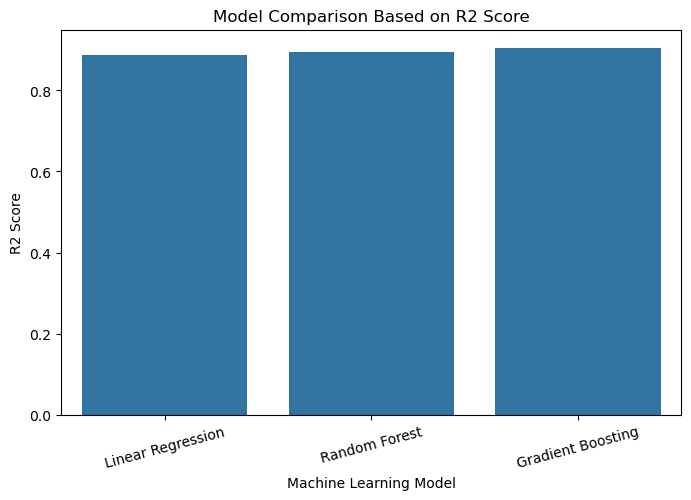

In [64]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='R2 Score'
)

plt.title("Model Comparison Based on R2 Score")
plt.xlabel("Machine Learning Model")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)

plt.show()

### 8.4 Actual vs Predicted Sale Price

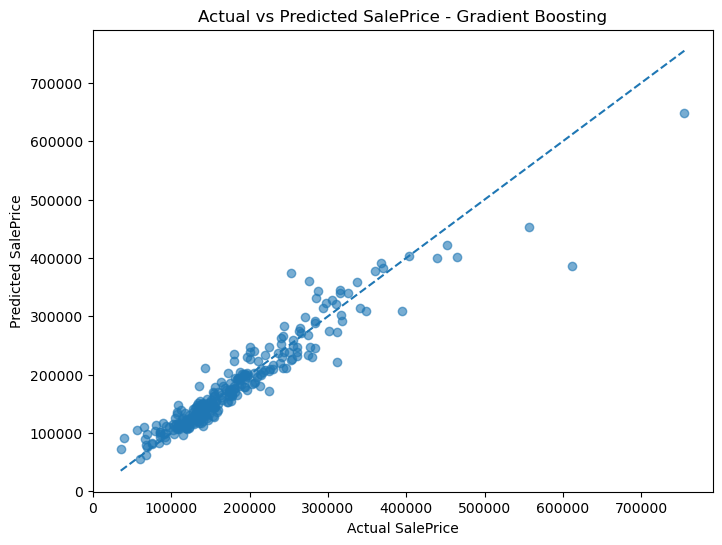

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_gb, alpha=0.6)

plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted SalePrice - Gradient Boosting")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

## 9. Model Comparison Report

Multiple machine learning regression models were trained and evaluated using MAE, RMSE and R² Score.

MAE measures the average absolute prediction error, while RMSE gives higher importance to larger errors. R² Score indicates how well the model explains the variation in house prices.

The model with the best overall evaluation performance is selected as the final model for house price prediction.

## 10. Customer House Buying Suggestions

Based on the analysis, customers should consider factors such as overall house quality, living area, location, basement area, garage facilities and construction year while evaluating a property.

Higher-quality houses and properties with larger living areas generally tend to have higher sale prices. Therefore, customers should compare these features with their available budget before making a purchase decision.

## 11. Challenges Faced and Techniques Used

### Challenges:
- Missing values were present in several features.
- The dataset contains both numerical and categorical variables.
- Different numerical features have different scales.
- Categorical variables cannot be directly used by most machine learning models.
- Some features have a large number of categories.

### Techniques Used:
- Missing numerical values were handled using median imputation.
- Missing categorical values were handled using the most frequent value.
- Categorical variables were converted into numerical form using One-Hot Encoding.
- Numerical features were standardized using StandardScaler.
- Multiple regression models were trained and compared using MAE, RMSE and R² Score.

## 12. Conclusion

The House Price Prediction project analyzed the major factors associated with residential property prices and developed machine learning models for predicting house sale prices.

Different regression models were trained and evaluated using MAE, RMSE and R² Score. Based on the evaluation results, the best-performing model was selected as the final model for house price prediction.

The analysis also provides useful insights into the relationship between house characteristics and their sale prices, which can help customers make better house-buying decisions.